# Como o contato entre os grãos cria o atrito do solo — simulação DEM do zero

Neste caderno você vai **construir um simulador de Elementos Discretos (DEM)** em Python e usá-lo para responder uma pergunta de geotecnia:

> **Se eu mudo o atrito entre dois grãos (μ), o que acontece com o ângulo de atrito do solo (φ)?**

Roteiro:
1. A ideia do DEM: o solo como um conjunto de grãos
2. O que acontece num único contato (mola + atrito de Coulomb)
3. O código do simulador, parte por parte
4. Primeiro teste: grãos caindo numa caixa
5. O ensaio de cisalhamento virtual (como um cisalhamento direto)
6. Experimento: φ do solo × μ entre grãos × resistência ao rolamento
7. O que os resultados ensinam
8. Exercícios e próximos passos (YADE, PFC, calibração)

**Como usar:** no Google Colab, vá em *Ambiente de execução → Executar tudo*. Só usa NumPy, SciPy e Matplotlib, que já vêm instalados.
As simulações são 2D e pequenas (centenas de grãos): servem para **entender o mecanismo**, não para projeto.

## 1. A ideia do DEM

No Método dos Elementos Discretos (Cundall & Strack, 1979), o solo não é um meio contínuo: é um **conjunto de grãos** que se tocam. A cada pequeno passo de tempo Δt o programa repete três coisas:

1. **Detectar os contatos**: quais pares de grãos estão se tocando (se sobrepondo um pouquinho).
2. **Calcular as forças em cada contato**: uma força **normal** que empurra os grãos para longe e uma força **tangencial** (o atrito) que resiste ao deslizamento.
3. **Mover os grãos**: somar as forças em cada grão e aplicar a 2ª lei de Newton (F = m·a) e sua versão para rotação (M = I·α).

Todo o comportamento do "solo" — resistência, dilatância, ângulo de atrito — **surge** dessas regras simples aplicadas a milhares de contatos. O ângulo de atrito φ **não é um dado de entrada**: ele é um **resultado**.

## 2. Um único contato

Dois grãos de raios $R_i$ e $R_j$ se tocam quando a distância entre os centros é menor que $R_i + R_j$. A **sobreposição** é

$$\delta = R_i + R_j - |\mathbf{x}_j - \mathbf{x}_i|$$

**Força normal** (mola + amortecedor):
$$F_n = k_n\,\delta + \gamma_n\, v_n \qquad (F_n \ge 0)$$

**Força tangencial — o atrito entre grãos.** Uma mola tangencial acumula o deslocamento relativo $\xi$ no ponto de contato, mas a força nunca passa do limite de Coulomb:
$$F_t = -k_t\,\xi \qquad \text{com} \qquad |F_t| \le \mu\,F_n$$

Enquanto $|k_t\xi| < \mu F_n$, o contato está **grudado** (só deforma). Quando atinge $\mu F_n$, o contato **escorrega**. Veja no gráfico:

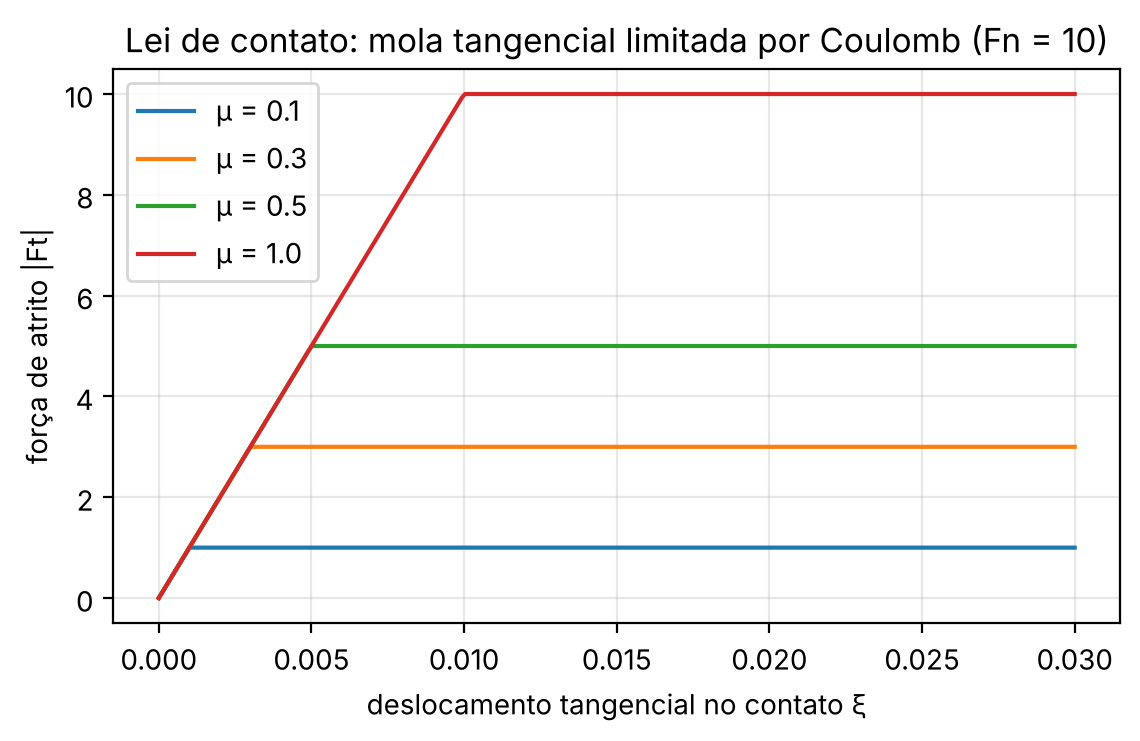

In [1]:
import numpy as np, matplotlib.pyplot as plt
Fn, kt = 10.0, 1000.0
xi = np.linspace(0, 0.03, 300)
plt.figure(figsize=(6.5, 3.6))
for mu in (0.1, 0.3, 0.5, 1.0):
    plt.plot(xi, np.minimum(kt * xi, mu * Fn), label=f"μ = {mu}")
plt.xlabel("deslocamento tangencial no contato ξ"); plt.ylabel("força de atrito |Ft|")
plt.title("Lei de contato: mola tangencial limitada por Coulomb (Fn = 10)")
plt.legend(); plt.grid(alpha=.3); plt.show()

**Resistência ao rolamento.** Discos lisos rolam com muita facilidade; grãos reais são angulosos e "travam". Um jeito simples de imitar a forma é um **momento** que resiste à rotação relativa, também limitado:
$$|M_r| \le \mu_r\,R_{ef}\,F_n$$

Com isso o modelo tem dois parâmetros de "atrito" no contato: **μ** (deslizamento) e **μ_r** (rolamento).

**Passo de tempo.** O contato é uma mola de massa *m* e rigidez *k_n*: para a simulação ser estável, Δt precisa ser bem menor que o período dessa mola, $\Delta t \approx 0{,}1\sqrt{m/k_n}$.

## 3. O simulador

A célula abaixo grava o arquivo `dem2d.py`. Os pontos principais:

* **`contatos()`** — usa uma árvore de busca (`cKDTree`) para achar pares próximos sem testar todos contra todos; também trata paredes e a caixa **periódica** (o que sai pela direita entra pela esquerda).
* **`passo()`** — calcula (a) a força normal, (b) o atrito tangencial com memória do contato, (c) o momento de rolamento; soma tudo em cada grão (ação e reação) e integra o movimento.
* **memória dos contatos** — a mola tangencial precisa "lembrar" quanto já foi deformada desde que o contato começou. Isso é guardado num dicionário par → ξ (aqui, arrays ordenados para ficar rápido).
* **`ensaio_cisalhamento()`** — monta e roda o ensaio da seção 5.

Leia os comentários: cada linha da física está marcada.

In [2]:
%%writefile dem2d.py
"""
dem2d.py — simulador de Elementos Discretos (DEM) 2D, didático, em Python + NumPy + SciPy.

Grãos = discos. Em cada contato entre dois grãos:
  * força normal ......... mola linear (kn) + amortecedor  -> os grãos se empurram
  * força tangencial ..... mola (kt) limitada por Coulomb   -> ATRITO ENTRE GRÃOS:  |Ft| <= mu * Fn
  * momento de rolamento . mola limitada                    -> imita grãos angulosos: |M| <= mu_r * R * Fn

Unidades adimensionais: diâmetro médio ~ 1, densidade = 1.
Recursos: gravidade, chão e paredes laterais opcionais, caixa periódica em x,
grãos fixos (fundo rugoso) e uma "placa" de grãos que se move junta (ensaio de cisalhamento).
"""
import numpy as np
from scipy.spatial import cKDTree


class DEM2D:
    def __init__(self, raios, x, y, mu=0.5, mu_r=0.0, kn=2.0e3, kt_kn=0.5, restituicao=0.3,
                 g=1.0, chao=True, parede_esq=None, parede_dir=None, periodo_x=None,
                 fixo=None, placa=None):
        self.N = len(raios)
        self.r = np.asarray(raios, float)
        self.m = np.pi * self.r**2                      # massa (densidade 1)
        self.I = 0.5 * self.m * self.r**2               # momento de inércia do disco
        self.pos = np.column_stack([x, y]).astype(float)
        self.vel = np.zeros((self.N, 2))
        self.w = np.zeros(self.N)                       # rotação
        self.mu, self.mu_r = mu, mu_r
        self.kn, self.kt = kn, kt_kn * kn
        self.g, self.chao = g, chao
        self.parede_esq, self.parede_dir = parede_esq, parede_dir   # posição x ou None
        self.Lx = periodo_x                             # caixa periódica em x (None = não)
        self.fixo = np.zeros(self.N, bool) if fixo is None else np.asarray(fixo, bool)
        self.placa = np.zeros(self.N, bool) if placa is None else np.asarray(placa, bool)
        e = restituicao
        self.zeta = -np.log(e) / np.sqrt(np.pi**2 + np.log(e)**2)   # amortecimento a partir de e
        livres = ~(self.fixo | self.placa)
        self.dt = 0.1 * np.sqrt(self.m[livres].min() / kn)        # passo de tempo estável
        self.t = 0.0
        # memória das molas de cada contato (chave do par -> deslocamento acumulado)
        self.chaves = np.zeros(0, np.int64)
        self.xi = np.zeros(0)
        self.th = np.zeros(0)
        # placa (ensaio de cisalhamento): velocidade horizontal imposta e pressão vertical
        self.V_placa, self.P_placa, self.vy_placa = 0.0, 0.0, 0.0
        self.F_placa = np.zeros(2)                      # força dos grãos sobre a placa

    # ------------------------------------------------------------------ 1) contatos
    def contatos(self):
        N, p, r = self.N, self.pos, self.r
        if self.Lx is None:
            arvore = cKDTree(p)
        else:
            q = p.copy(); q[:, 0] %= self.Lx
            q[:, 1] -= p[:, 1].min() - 1
            arvore = cKDTree(q, boxsize=[self.Lx, 10 * (q[:, 1].max() + 10)])
        pares = arvore.query_pairs(2 * r.max(), output_type="ndarray")
        i, j = pares[:, 0], pares[:, 1]
        d = p[j] - p[i]
        if self.Lx is not None:                         # imagem mais próxima (caixa periódica)
            d[:, 0] -= self.Lx * np.round(d[:, 0] / self.Lx)
        dist = np.hypot(d[:, 0], d[:, 1])
        ov = r[i] + r[j] - dist                         # sobreposição
        rigido = self.fixo | self.placa
        ok = (ov > 0) & ~(rigido[i] & rigido[j])
        i, j, d, dist, ov = i[ok], j[ok], d[ok], dist[ok], ov[ok]
        n = d / dist[:, None]                           # normal unitária de i para j
        listas = [(i, j, n, ov, r[j])]
        # paredes = "grãos" de índice N (chão), N+1 (esquerda), N+2 (direita)
        paredes = []
        if self.chao:
            paredes.append((N, p[:, 1] < r, (0.0, -1.0), r - p[:, 1]))
        if self.parede_esq is not None:
            paredes.append((N + 1, p[:, 0] < self.parede_esq + r, (-1.0, 0.0), r - (p[:, 0] - self.parede_esq)))
        if self.parede_dir is not None:
            paredes.append((N + 2, p[:, 0] > self.parede_dir - r, (1.0, 0.0), r - (self.parede_dir - p[:, 0])))
        for idw, sel, nn, ovw in paredes:
            k = np.nonzero(sel & ~rigido)[0]
            listas.append((k, np.full(len(k), idw), np.tile(nn, (len(k), 1)), ovw[k], np.zeros(len(k))))
        return [np.concatenate(a) for a in zip(*listas)]

    # ------------------------------------------------------------------ 2) forças + 3) movimento
    def passo(self):
        N, dt = self.N, self.dt
        I, J, n, ov, rJ = self.contatos()
        t = np.column_stack([-n[:, 1], n[:, 0]])        # direção tangencial
        parede = J >= N
        Jp = np.where(parede, 0, J)
        vJ = np.where(parede[:, None], 0.0, self.vel[Jp])
        wJ = np.where(parede, 0.0, self.w[Jp])
        mJ = np.where(parede, np.inf, self.m[Jp])
        m_ef = 1.0 / (1.0 / self.m[I] + 1.0 / mJ)
        rI = self.r[I]

        dv = self.vel[I] - vJ
        vn = np.einsum("ij,ij->i", dv, n)                # > 0: grãos se aproximando
        vt = np.einsum("ij,ij->i", dv, t) + self.w[I] * rI + wJ * rJ   # deslizamento no ponto de contato

        # (a) NORMAL: mola + amortecedor; nunca puxa (Fn >= 0)
        Fn = np.maximum(self.kn * ov + 2 * self.zeta * np.sqrt(m_ef * self.kn) * vn, 0.0)

        # recuperar a memória das molas dos contatos que já existiam
        chave = I.astype(np.int64) * (N + 3) + J
        xi = np.zeros(len(I)); th = np.zeros(len(I))
        if len(self.chaves):
            k = np.minimum(np.searchsorted(self.chaves, chave), len(self.chaves) - 1)
            achou = self.chaves[k] == chave
            xi[achou] = self.xi[k[achou]]; th[achou] = self.th[k[achou]]

        # (b) TANGENCIAL: mola limitada pelo atrito de Coulomb |Ft| <= mu*Fn
        xi = xi + vt * dt
        Ft = -self.kt * xi
        limite = self.mu * Fn
        desliza = np.abs(Ft) > limite
        Ft[desliza] = np.sign(Ft[desliza]) * limite[desliza]
        xi[desliza] = -Ft[desliza] / self.kt             # o contato escorrega

        # (c) ROLAMENTO: momento limitado |M| <= mu_r*R*Fn
        R_ef = np.where(parede, rI, rI * rJ / np.maximum(rI + rJ, 1e-12))
        kr = self.kt * R_ef**2
        th = th + (self.w[I] - wJ) * dt
        M = -kr * th
        limr = self.mu_r * R_ef * Fn
        rola = np.abs(M) > limr
        M[rola] = np.sign(M[rola]) * limr[rola]
        th[rola] = -M[rola] / np.maximum(kr[rola], 1e-12)

        o = np.argsort(chave)
        self.chaves, self.xi, self.th = chave[o], xi[o], th[o]

        # somar forças e momentos (ação e reação)
        F = -Fn[:, None] * n + Ft[:, None] * t
        Ftot = np.zeros((N, 2)); Ttot = np.zeros(N)
        np.add.at(Ftot, I, F); np.add.at(Ttot, I, rI * Ft + M)
        g = ~parede
        np.add.at(Ftot, J[g], -F[g]); np.add.at(Ttot, J[g], rJ[g] * Ft[g] - M[g])
        Ftot[:, 1] -= self.m * self.g                    # gravidade

        # integrar (Euler semi-implícito)
        self.vel += Ftot / self.m[:, None] * dt
        self.w += Ttot / self.I * dt
        self.vel[self.fixo] = 0.0; self.w[self.fixo] = 0.0
        if self.placa.any():                             # a placa anda como um corpo rígido
            self.F_placa = Ftot[self.placa].sum(0)
            Mp = self.m[self.placa].sum()
            amort = 2 * np.sqrt(Mp * self.kn * self.placa.sum())   # evita oscilação da placa
            self.vy_placa += (self.F_placa[1] - self.P_placa - amort * self.vy_placa) / Mp * dt
            self.vel[self.placa] = (self.V_placa, self.vy_placa); self.w[self.placa] = 0.0
        self.pos += self.vel * dt
        self.t += dt

    # ------------------------------------------------------------------ utilidades
    def energia_cinetica_media(self):
        L = ~(self.fixo | self.placa)
        return (0.5 * np.sum(self.m[L] * np.sum(self.vel[L]**2, 1)) + 0.5 * np.sum(self.I[L] * self.w[L]**2)) / L.sum()

    def rodar(self, tempo, parar_quando_parado=False, ek_min=1e-4, a_cada=500, ao_registrar=None):
        for k in range(int(tempo / self.dt)):
            self.passo()
            if k % a_cada == 0:
                if ao_registrar is not None:
                    ao_registrar(self)
                if parar_quando_parado and k > 4 * a_cada and self.energia_cinetica_media() < ek_min:
                    break
        return self


# ====================================================================== montagens prontas
def caixa_cisalhamento(Lx=24, n_camadas=16, seed=0):
    """Camada de grãos entre um fundo rugoso fixo e uma placa rugosa no topo; periódica em x."""
    rng = np.random.default_rng(seed)
    dr = 0.5                                             # grãos da rugosidade: diâmetro 0,5
    xr = np.arange(0.25, Lx, dr)
    nx = int(Lx / 1.1)
    xs, ys = np.meshgrid((np.arange(nx) + 0.5) * Lx / nx, 1.0 + np.arange(n_camadas) * 1.15)
    r = rng.uniform(0.4, 0.6, xs.size)                  # diâmetros entre 0,8 e 1,2
    topo = ys.max() + 1.0
    raios = np.concatenate([np.full(xr.size, dr / 2), r, np.full(xr.size, dr / 2)])
    X = np.concatenate([xr, xs.ravel() + rng.uniform(-0.05, 0.05, xs.size), xr])
    Y = np.concatenate([np.full(xr.size, 0.0), ys.ravel(), np.full(xr.size, topo)])
    fixo = np.r_[np.ones(xr.size, bool), np.zeros(xs.size + xr.size, bool)]
    placa = np.r_[np.zeros(xr.size + xs.size, bool), np.ones(xr.size, bool)]
    return raios, X, Y, fixo, placa


def ensaio_cisalhamento(mu, mu_r=0.0, sigma=10.0, Lx=24, n_camadas=16, I_inercial=0.005,
                        deformacao=2.0, seed=0, registrar=None):
    """Cisalhamento plano com tensão normal constante.
    Devolve a simulação e um histórico com colunas: tempo, deformação, tau/sigma, espessura."""
    raios, X, Y, fixo, placa = caixa_cisalhamento(Lx, n_camadas, seed)
    s = DEM2D(raios, X, Y, mu=mu, mu_r=mu_r, g=0.0, chao=False, periodo_x=Lx, fixo=fixo, placa=placa)
    s.P_placa = sigma * Lx                               # força normal total sobre a placa
    # 1) adensar: a placa desce sob a tensão normal, sem cisalhar
    s.rodar(30)
    H = s.pos[placa, 1].mean() - s.pos[fixo, 1].mean()
    # 2) cisalhar: placa anda com velocidade V.  Número inercial I = (V/H)*d / sqrt(sigma/densidade)
    s.V_placa = I_inercial * np.sqrt(sigma) * H
    hist = []
    t0 = s.t
    def reg(sim):
        Hs = sim.pos[placa, 1].mean() - sim.pos[fixo, 1].mean()
        hist.append((sim.t - t0, sim.V_placa * (sim.t - t0) / Hs, -sim.F_placa[0] / sim.P_placa, Hs))
        if registrar:
            registrar(sim)
    s.rodar(deformacao * H / s.V_placa, ao_registrar=reg, a_cada=200)
    return s, np.array(hist)


Writing dem2d.py


In [3]:
import importlib, dem2d; importlib.reload(dem2d)
from dem2d import DEM2D, ensaio_cisalhamento
from matplotlib.collections import PatchCollection
from matplotlib.patches import Circle

def desenhar(sim, cor=None, ax=None, titulo="", cmap="viridis", lim=None):
    ax = ax or plt.gca()
    p = sim.pos.copy()
    if sim.Lx is not None: p[:, 0] %= sim.Lx
    circs = [Circle(xy, r) for xy, r in zip(p, sim.r)]
    pc = PatchCollection(circs, cmap=cmap, edgecolor="k", linewidth=0.2)
    pc.set_array(np.zeros(sim.N) if cor is None else cor)
    if lim is not None: pc.set_clim(*lim)
    ax.add_collection(pc); ax.set_aspect("equal"); ax.autoscale_view(); ax.set_title(titulo); ax.axis("off")
    return pc
print("simulador carregado")

simulador carregado


## 4. Primeiro teste: grãos caindo numa caixa

Antes de medir qualquer coisa, sempre teste o simulador num caso simples. Aqui 200 grãos caem sob gravidade numa caixa. Esperamos que: (1) eles se acomodem sem "explodir" (passo de tempo estável), (2) a energia cinética caia até perto de zero e (3) as sobreposições fiquem pequenas (≈ 1% do diâmetro).

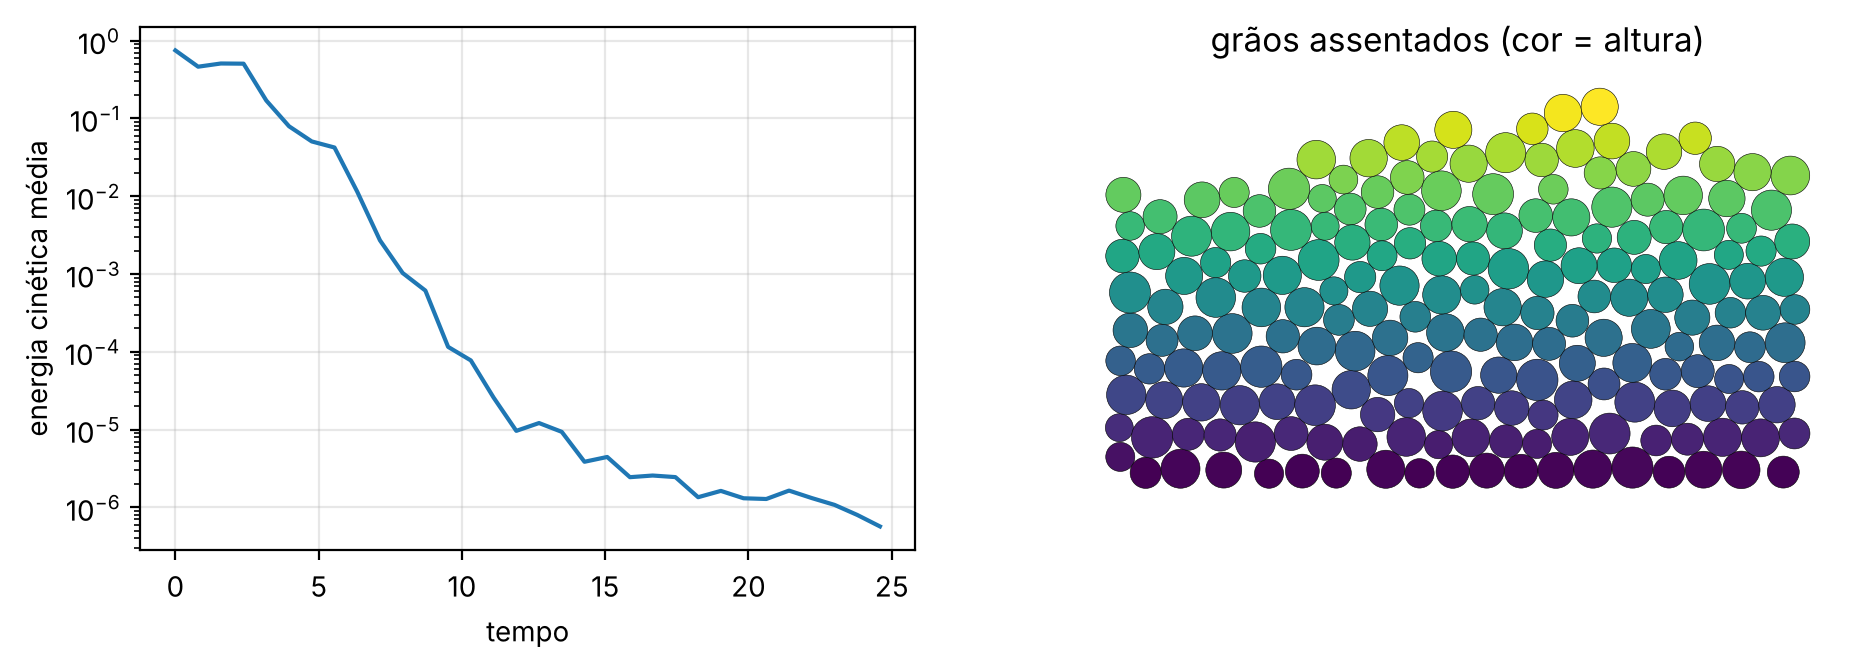

passo de tempo Δt = 0.0016  |  sobreposição máxima = 0.0176 (diâmetro ≈ 1)


In [4]:
rng = np.random.default_rng(3)
xs, ys = np.meshgrid(np.arange(20) + 0.6, np.arange(10) * 1.3 + 1)
r = rng.uniform(0.4, 0.6, xs.size)
caixa = DEM2D(r, xs.ravel(), ys.ravel(), mu=0.5, g=1.0, parede_esq=0.0, parede_dir=20.2)
caixa.vel[:] = rng.normal(0, 1, (caixa.N, 2))          # empurrão inicial aleatório

energia, tempos = [], []
caixa.rodar(25, ao_registrar=lambda s: (energia.append(s.energia_cinetica_media()), tempos.append(s.t)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].semilogy(tempos, energia); ax[0].set_xlabel("tempo"); ax[0].set_ylabel("energia cinética média"); ax[0].grid(alpha=.3)
I, J, n, ov, rJ = caixa.contatos()
desenhar(caixa, cor=caixa.pos[:, 1], ax=ax[1], titulo="grãos assentados (cor = altura)")
plt.show()
print(f"passo de tempo Δt = {caixa.dt:.4f}  |  sobreposição máxima = {ov.max():.4f} (diâmetro ≈ 1)")

## 5. O ensaio de cisalhamento virtual

No laboratório, o ângulo de atrito vem do **cisalhamento direto** ou do **triaxial**: aplica-se uma tensão normal σ, cisalha-se a amostra e mede-se a tensão cisalhante τ. Então
$$\tan\varphi = \frac{\tau}{\sigma}$$

Aqui fazemos o equivalente em DEM, o **cisalhamento plano**:

* uma camada de grãos entre um **fundo rugoso fixo** e uma **placa rugosa** no topo;
* a placa aplica uma **tensão normal constante σ** (ela pode subir ou descer — assim vemos a **dilatância**);
* a placa anda para o lado com velocidade constante e medimos a força horizontal que os grãos fazem sobre ela → τ;
* a caixa é **periódica** na horizontal (não há paredes laterais atrapalhando);
* sem gravidade, para a tensão ser uniforme.

A velocidade é escolhida pelo **número inercial** $I = \dot\gamma\, d / \sqrt{\sigma/\rho}$. Com $I$ pequeno (aqui 0,005) o ensaio é praticamente **quase-estático**, como no laboratório.

A célula abaixo roda **um** ensaio com μ = 0,5 (leva cerca de 1 minuto).

levou 56 s, 432 grãos
τ/σ no regime estável = 0.233  →  φ = 13.1°   (μ entre grãos = 0,5 → 26.6°)


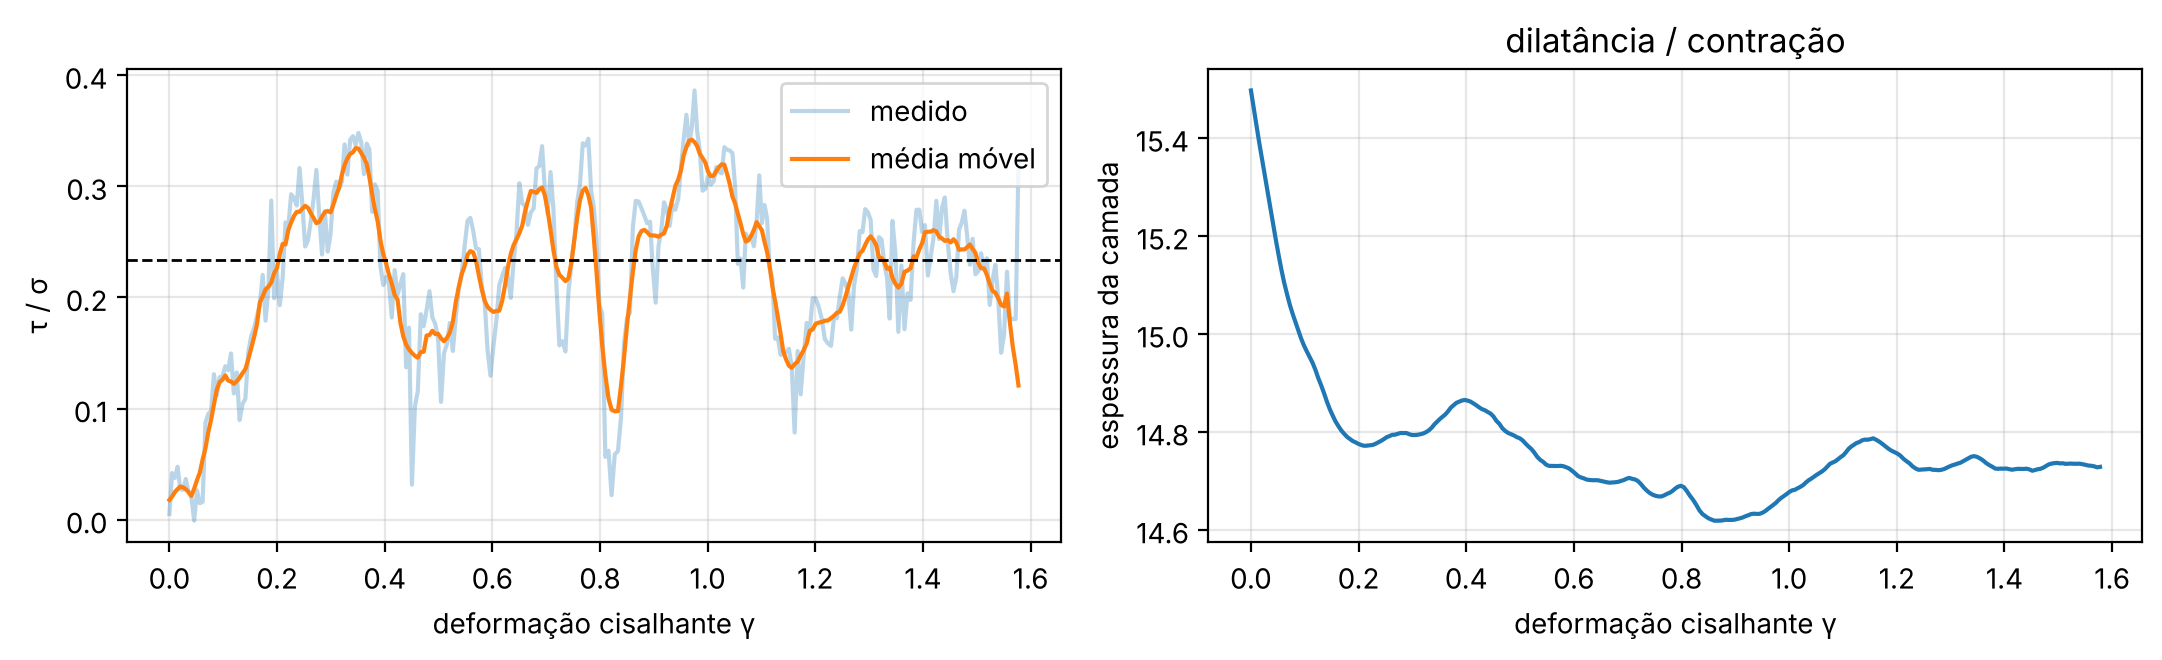

In [5]:
import time
fotos = []
def guardar_fotos(sim):
    if len(fotos) == 0 or sim.t - fotos[-1][0] > 25:
        fotos.append((sim.t, sim.pos.copy(), sim.vel[:, 0].copy()))

t0 = time.time()
sim, hist = ensaio_cisalhamento(mu=0.5, mu_r=0.0, sigma=10, deformacao=1.5, registrar=guardar_fotos)
print(f"levou {time.time() - t0:.0f} s, {sim.N} grãos")

estavel = hist[:, 1] > 0.5
razao = hist[estavel, 2].mean()
print(f"τ/σ no regime estável = {razao:.3f}  →  φ = {np.degrees(np.arctan(razao)):.1f}°   (μ entre grãos = 0,5 → {np.degrees(np.arctan(0.5)):.1f}°)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
suave = np.convolve(hist[:, 2], np.ones(9) / 9, mode="same")
ax[0].plot(hist[:, 1], hist[:, 2], alpha=.3, label="medido"); ax[0].plot(hist[:, 1], suave, label="média móvel")
ax[0].axhline(razao, ls="--", c="k", lw=1); ax[0].set_xlabel("deformação cisalhante γ"); ax[0].set_ylabel("τ / σ"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(hist[:, 1], hist[:, 3]); ax[1].set_xlabel("deformação cisalhante γ"); ax[1].set_ylabel("espessura da camada"); ax[1].set_title("dilatância / contração"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

Os grãos coloridos pela **velocidade horizontal**: em cima andam com a placa (amarelo), embaixo ficam parados (roxo). O perfil de velocidade mostra como a deformação se distribui na camada.

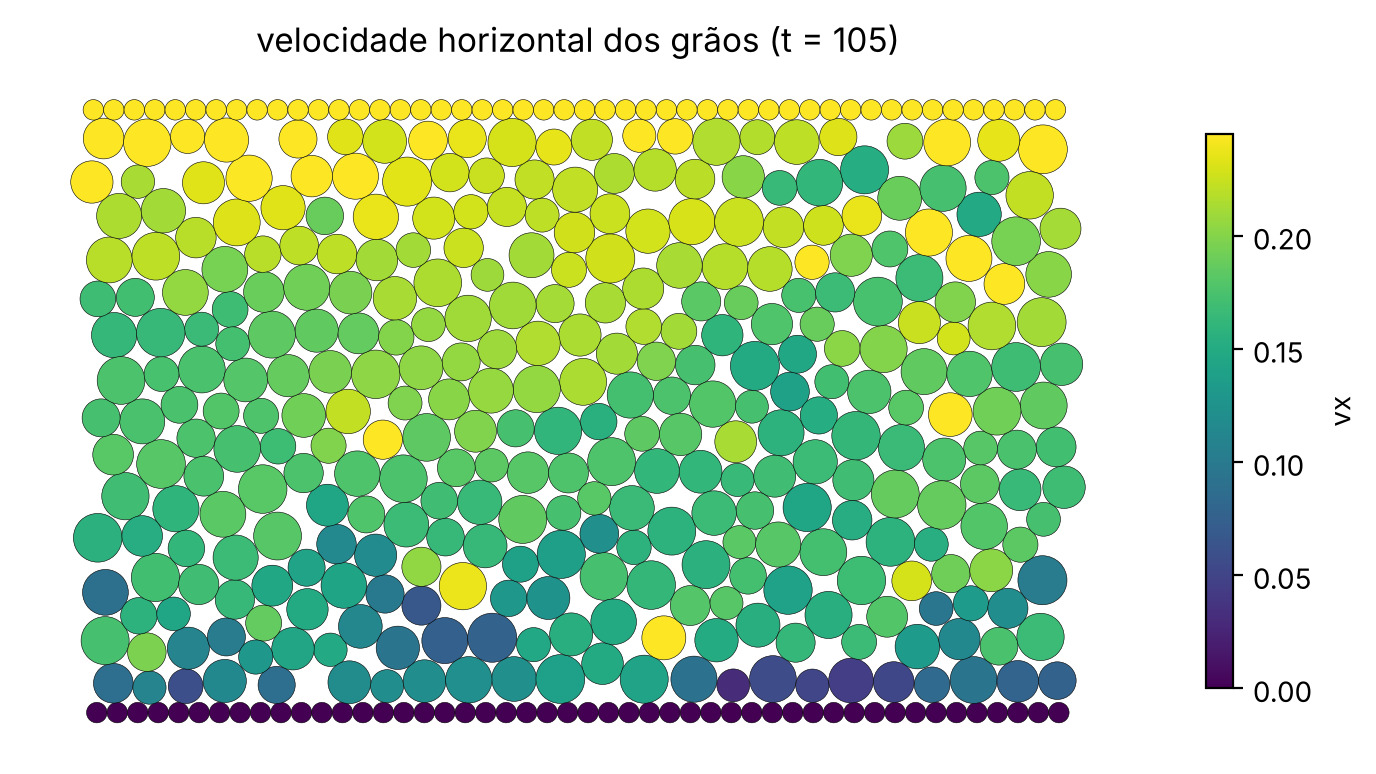

In [6]:
t, p, vx = fotos[-1]
sim.pos[:] = p
fig = plt.figure(figsize=(9, 6))
pc = desenhar(sim, cor=vx, titulo=f"velocidade horizontal dos grãos (t = {t:.0f})", lim=(0, sim.V_placa))
plt.colorbar(pc, shrink=.6, label="vx"); plt.show()

## 6. Experimento: φ do solo × μ entre grãos

Agora repetimos o ensaio variando:
* **μ** (atrito de deslizamento entre grãos): 0 a 1
* **μ_r** (resistência ao rolamento, que imita a angulosidade): 0, 0,1 e 0,3

São 21 ensaios. Rodar todos leva ~40 minutos no Colab, então **os resultados já vêm prontos** na célula abaixo (gerados com este mesmo código). Para rodar você mesmo, mude `RODAR = True`.

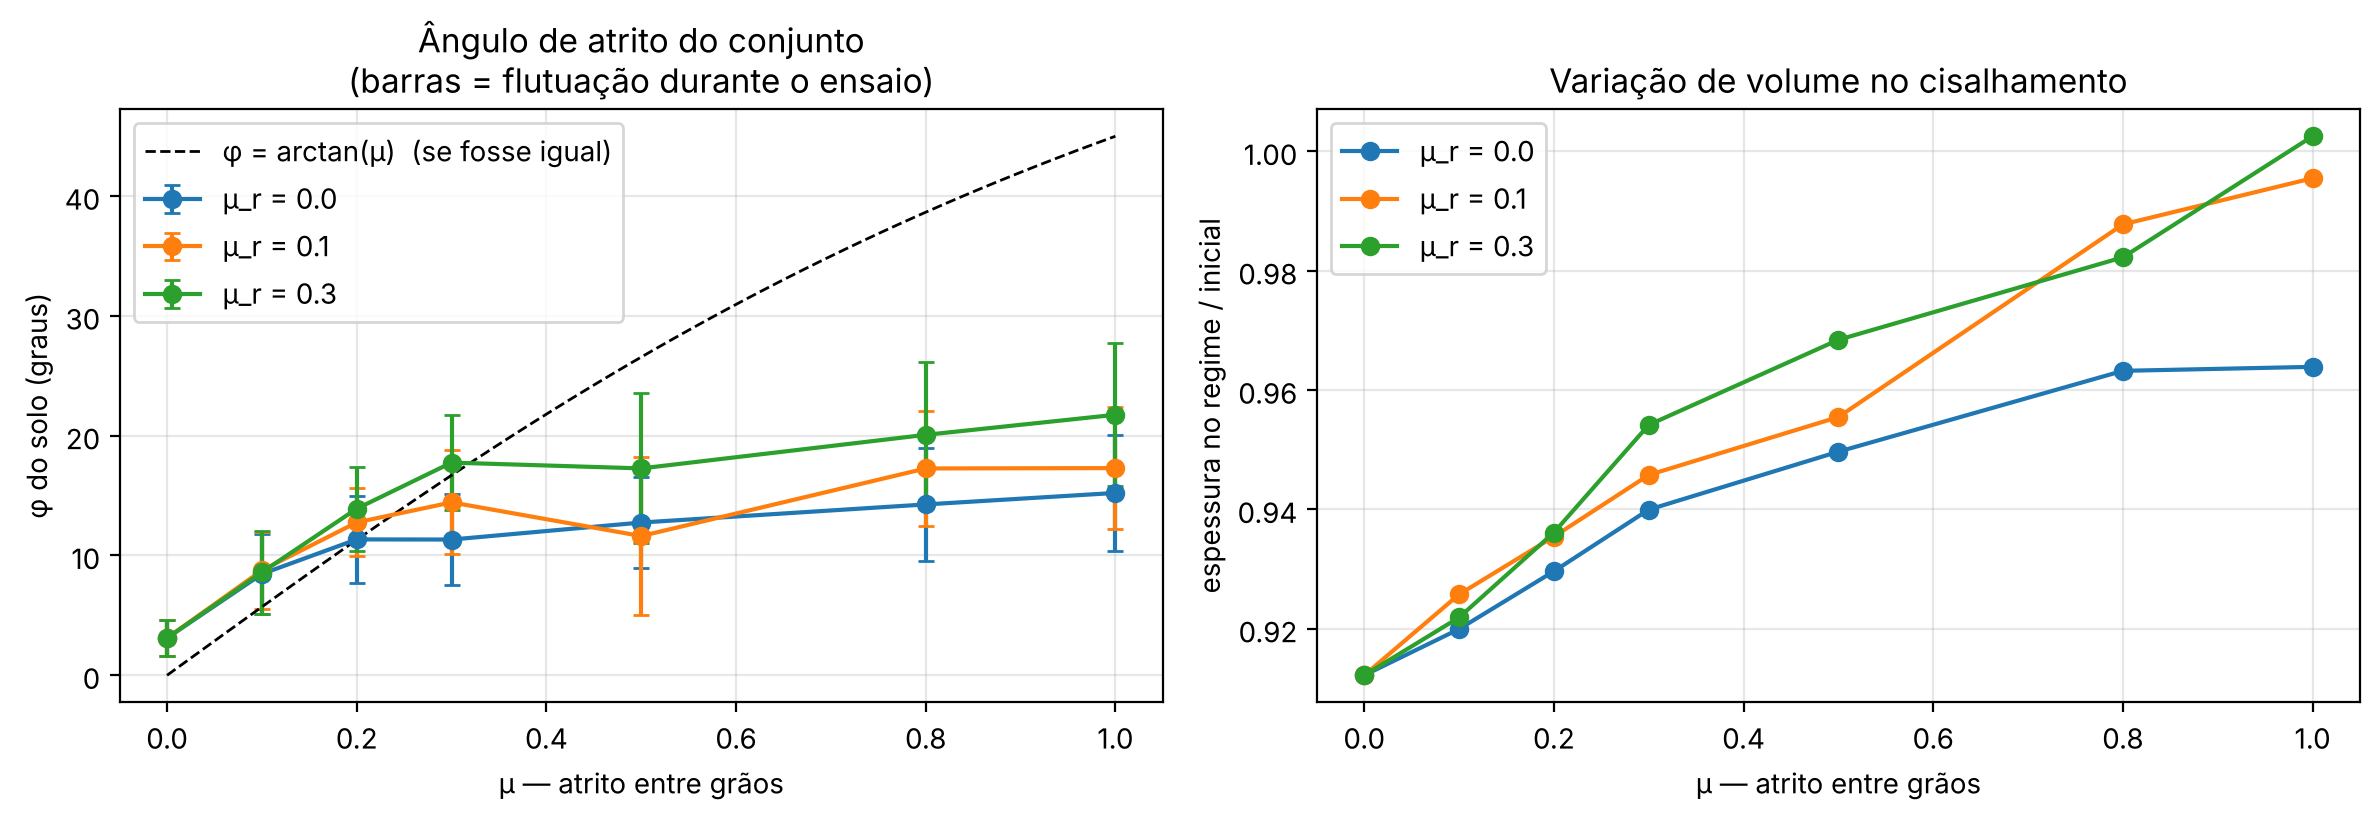

 μ    μ_r   τ/σ    φ (graus)
 0.0   0.0  0.054    3.1
 0.1   0.0  0.149    8.5
 0.2   0.0  0.201   11.3
 0.3   0.0  0.200   11.3
 0.5   0.0  0.226   12.8
 0.8   0.0  0.254   14.3
 1.0   0.0  0.272   15.2
 0.0   0.1  0.054    3.1
 0.1   0.1  0.154    8.8
 0.2   0.1  0.227   12.8
 0.3   0.1  0.257   14.4
 0.5   0.1  0.206   11.6
 0.8   0.1  0.311   17.3
 1.0   0.1  0.311   17.3
 0.0   0.3  0.054    3.1
 0.1   0.3  0.151    8.6
 0.2   0.3  0.248   13.9
 0.3   0.3  0.320   17.8
 0.5   0.3  0.311   17.3
 0.8   0.3  0.365   20.1
 1.0   0.3  0.399   21.7


In [7]:
RODAR = False   # True = rodar os 21 ensaios (~40 min)

# resultados pré-calculados: (mu, mu_r, tau/sigma, desvio, espessura inicial, espessura no regime)
PRONTOS = [[0.0, 0.0, 0.0544, 0.0259, 15.49, 14.13], [0.1, 0.0, 0.1487, 0.0595, 15.49, 14.25], [0.2, 0.0, 0.2006, 0.0656, 15.49, 14.4], [0.3, 0.0, 0.2004, 0.0692, 15.49, 14.56], [0.5, 0.0, 0.2263, 0.0698, 15.5, 14.72], [0.8, 0.0, 0.2542, 0.0881, 15.5, 14.93], [1.0, 0.0, 0.2721, 0.0914, 15.51, 14.95], [0.0, 0.1, 0.0544, 0.0259, 15.49, 14.13], [0.1, 0.1, 0.1541, 0.057, 15.49, 14.34], [0.2, 0.1, 0.2265, 0.0522, 15.49, 14.49], [0.3, 0.1, 0.2574, 0.0808, 15.49, 14.65], [0.5, 0.1, 0.2057, 0.1197, 15.5, 14.81], [0.8, 0.1, 0.3108, 0.0917, 15.54, 15.35], [1.0, 0.1, 0.3114, 0.0981, 15.59, 15.52], [0.0, 0.3, 0.0544, 0.0259, 15.49, 14.13], [0.1, 0.3, 0.1512, 0.0615, 15.49, 14.28], [0.2, 0.3, 0.2476, 0.065, 15.5, 14.51], [0.3, 0.3, 0.3202, 0.0769, 15.49, 14.78], [0.5, 0.3, 0.3109, 0.1197, 15.52, 15.03], [0.8, 0.3, 0.3654, 0.1207, 15.78, 15.5], [1.0, 0.3, 0.3989, 0.121, 15.71, 15.75]]

if RODAR:
    resultados = []
    for mu_r in (0.0, 0.1, 0.3):
        for mu in (0.0, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0):
            s, h = ensaio_cisalhamento(mu, mu_r, deformacao=3.0)
            e = h[h[:, 1] > 0.5]
            resultados.append((mu, mu_r, e[:, 2].mean(), e[:, 2].std(), h[0, 3], e[:, 3].mean()))
            print(f"μ={mu:.1f} μ_r={mu_r:.1f}  τ/σ={e[:, 2].mean():.3f}")
else:
    resultados = PRONTOS
R = np.array(resultados, float)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for mu_r, cor in zip((0.0, 0.1, 0.3), ("tab:blue", "tab:orange", "tab:green")):
    s = R[R[:, 1] == mu_r]
    ax[0].errorbar(s[:, 0], np.degrees(np.arctan(s[:, 2])), yerr=np.degrees(s[:, 3] / (1 + s[:, 2]**2)),
                   marker="o", capsize=3, color=cor, label=f"μ_r = {mu_r}")
    ax[1].plot(s[:, 0], s[:, 5] / s[:, 4], marker="o", color=cor, label=f"μ_r = {mu_r}")
m = np.linspace(0, 1, 50)
ax[0].plot(m, np.degrees(np.arctan(m)), "k--", lw=1, label="φ = arctan(μ)  (se fosse igual)")
ax[0].set_xlabel("μ — atrito entre grãos"); ax[0].set_ylabel("φ do solo (graus)"); ax[0].set_title("Ângulo de atrito do conjunto\n(barras = flutuação durante o ensaio)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].set_xlabel("μ — atrito entre grãos"); ax[1].set_ylabel("espessura no regime / inicial"); ax[1].set_title("Variação de volume no cisalhamento"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print(" μ    μ_r   τ/σ    φ (graus)")
for mu, mu_r, ts, *_ in resultados:
    print(f"{mu:4.1f}  {mu_r:4.1f}  {ts:5.3f}  {np.degrees(np.arctan(ts)):5.1f}")

## 7. O que os resultados ensinam

1. **φ do solo ≠ arctan(μ).** O ângulo de atrito do conjunto é uma propriedade **coletiva**: depende de como os grãos se arranjam, deslizam, rolam e se travam.
2. **Mesmo com μ = 0 o solo tem atrito.** Grãos sem nenhum atrito de contato ainda resistem ao cisalhamento, porque precisam **subir uns sobre os outros** para passar (efeito geométrico, ligado à dilatância e ao arranjo).
3. **Aumentar μ ajuda, mas satura.** A partir de certo valor, os contatos deixam de escorregar e os grãos passam a **rolar**: o atrito extra no contato não é mais usado.
4. **Bloquear o rolamento (μ_r) aumenta muito φ.** É por isso que discos lisos em 2D dão φ baixos (≈ 15–20°) e as areias reais, com grãos angulosos, chegam a 30–40°. A **forma** dos grãos pesa tanto quanto o atrito da superfície.
5. **Densidade e dilatância.** No gráfico da direita, todas as camadas **contraíram** (razão < 1), porque o arranjo inicial era fofo. Mas quanto maior o atrito entre grãos, **menos** a camada contrai: o **estado crítico** de um material com mais atrito é mais fofo (mais vazios). É a mesma ideia do índice de vazios crítico da Mecânica dos Solos. Uma amostra mais densa no início faria o contrário: dilataria e teria um **pico** de resistência antes do regime estável.

**Cuidado com o ruído.** Com só ~430 grãos, cada ponto oscila uns ±2° (veja o ponto μ = 0,5, μ_r = 0,1, abaixo do vizinho). Em pesquisa, usa-se mais grãos, mais deformação e várias repetições com arranjos iniciais diferentes (`seed`), tirando a média.

Esses resultados repetem, em pequena escala, o que a literatura de DEM mostra com milhares de grãos em 3D.

## 8. Exercícios

1. **Tensão normal.** Rode `ensaio_cisalhamento(0.5, sigma=5)` e `sigma=20`. Em DEM sem coesão, φ quase não muda com σ. Por quê?
2. **Velocidade.** Mude `I_inercial` para 0,05 e 0,2. O ensaio fica "dinâmico" e τ/σ sobe — é a reologia μ(I) dos materiais granulares.
3. **Granulometria.** Em `caixa_cisalhamento`, troque `rng.uniform(0.4, 0.6, ...)` por `rng.uniform(0.25, 0.75, ...)` (solo mais bem graduado).
4. **Sucção (solo não saturado).** Acrescente em `passo()`, depois de calcular `Fn`, uma força de atração capilar constante entre grãos próximos: `Fn = Fn - F_cap` (com `F_cap` positivo e permitindo `Fn` negativo até `-F_cap`). Veja como a "coesão aparente" aparece: τ/σ sobe mais em σ baixo.
5. **Cimentação (solos lateríticos).** Crie ligações entre grãos que se tocam no início, com resistência à tração e ao cisalhamento; quebre a ligação quando a força passar do limite. Esse é o *bonded particle model*.

## Próximos passos para um trabalho de verdade

* **Simulações 3D e com milhares de grãos:** use um programa dedicado.
  * **YADE** (gratuito, Python, muito usado em geotecnia) — no Linux: `sudo apt install yade`.
  * **LIGGGHTS / LAMMPS**, **MercuryDPM** (gratuitos).
  * **PFC** (Itasca, comercial — padrão da indústria).
* **Calibração:** ajuste μ, μ_r, rigidez e distribuição de tamanhos para reproduzir ensaios reais (triaxial, cisalhamento direto, ângulo de repouso) do seu solo; só depois use o modelo para prever.
* **Leituras:**
  * Cundall, P. A. & Strack, O. D. L. (1979). *A discrete numerical model for granular assemblies.* Géotechnique 29(1).
  * O'Sullivan, C. (2011). *Particulate Discrete Element Modelling: A Geomechanics Perspective.* CRC Press.
  * GDR MiDi (2004). *On dense granular flows.* European Physical Journal E 14.
  * Ai, J. et al. (2011). *Assessment of rolling resistance models in discrete element simulations.* Powder Technology 206.